In [1]:
from pathlib import Path

project_root = Path.cwd().parent

In [2]:
import pandas as pd

combined_ledger = pd.read_csv(project_root / "data" / "processed" / "quarterly_ledger.csv")
combined_ledger['date'] = pd.to_datetime(combined_ledger['date'])

/tmp/ipykernel_12842/1860357661.py:4: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  combined_ledger['date'] = pd.to_datetime(combined_ledger['date'])


In [3]:
combined_ledger.describe(exclude=['datetime64'])

,revenue,deposit,repayment,principal_outstanding
count,24.000000,24.000000,24.000000,24.000000
mean,576105.917500,133188.194167,16034.204583,46543.727917
std,107053.675081,22405.451740,6206.790956,34084.074932
min,365486.370000,93982.640000,5992.480000,0.000000
25%,515352.105000,118323.465000,11451.035000,15220.710000
50%,570556.055000,135698.035000,16324.345000,49680.235000
75%,637715.587500,143587.492500,21562.005000,75128.857500
max,775709.880000,183397.650000,26593.340000,106216.780000


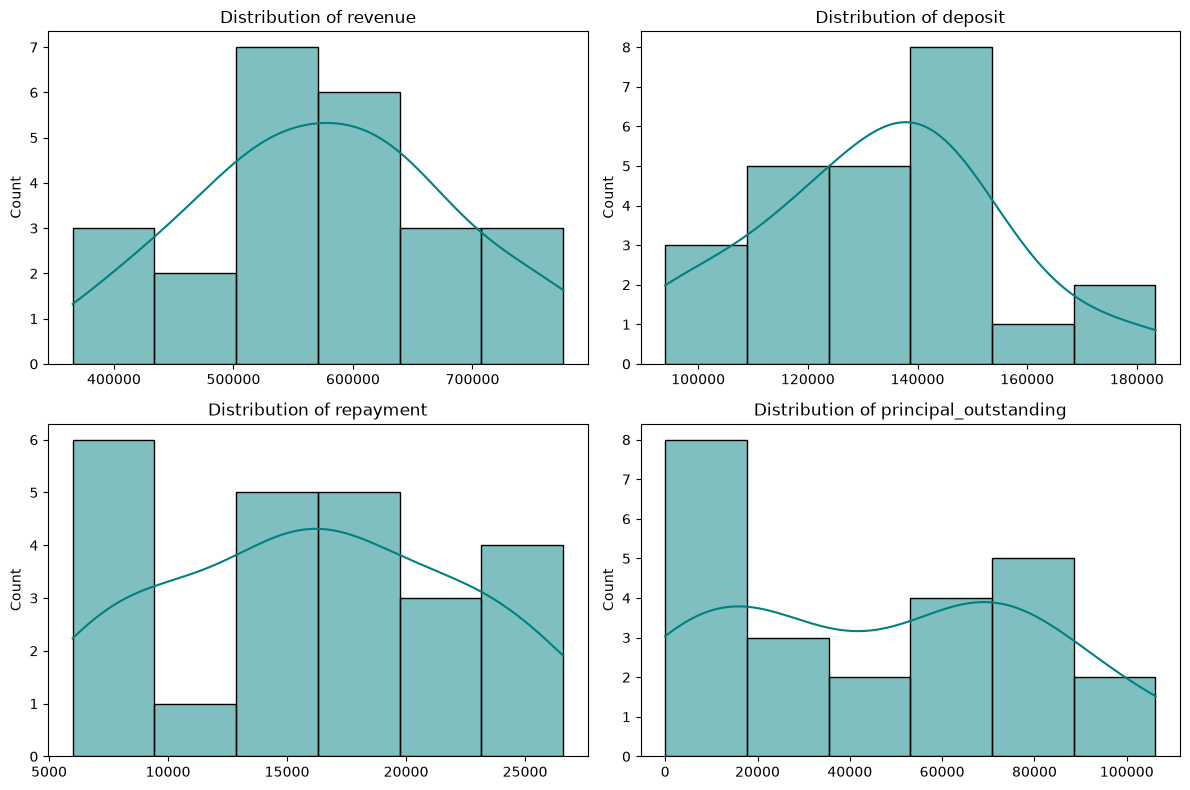

In [4]:
import math
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Filter out the date column (and any other non-numeric columns if needed)
cols_to_plot = [col for col in combined_ledger.columns if col != 'date']
num_cols = len(cols_to_plot)

# 2. Dynamically calculate grid layout (fixing 2 plots per row)
plots_per_row = 2
num_rows = math.ceil(num_cols / plots_per_row)

# 3. Create the subplots with the exact required rows
fig, axes = plt.subplots(num_rows, plots_per_row, figsize=(12, 4 * num_rows))

# Flatten axes for easy looping (handles both 1D and 2D arrays safely)
if num_rows * plots_per_row > 1:
    axes = axes.flatten()
else:
    axes = [axes]

# 4. Loop only through the filtered columns
for i, col in enumerate(cols_to_plot):
    sns.histplot(combined_ledger[col], kde=True, ax=axes[i], color='teal')
    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_xlabel('')

# 5. Hide any leftover completely empty subplots
for j in range(num_cols, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


In [5]:
def classify_period(date):
    if date < pd.Timestamp('2020Q2'):
        return 'pre_covid'
    elif date <= pd.Timestamp('2021Q1'):
        return 'during_covid'
    else:
        return 'post_covid'

In [6]:
combined_ledger['covid_period'] = combined_ledger['date'].apply(classify_period)

In [7]:
for period, group in combined_ledger.groupby('covid_period')['revenue']:
    print(period, group.values)

during_covid [421398.42 431929.89 512393.58 441220.96]
post_covid [528340.59 523203.81 630614.77 486330.4  573074.68 568037.43 695168.98
 531236.73 623500.64 636090.05 748406.14 553555.43 647618.57 642592.2
 775709.88]
pre_covid [516338.28 615524.98 616114.33 742654.91 365486.37]


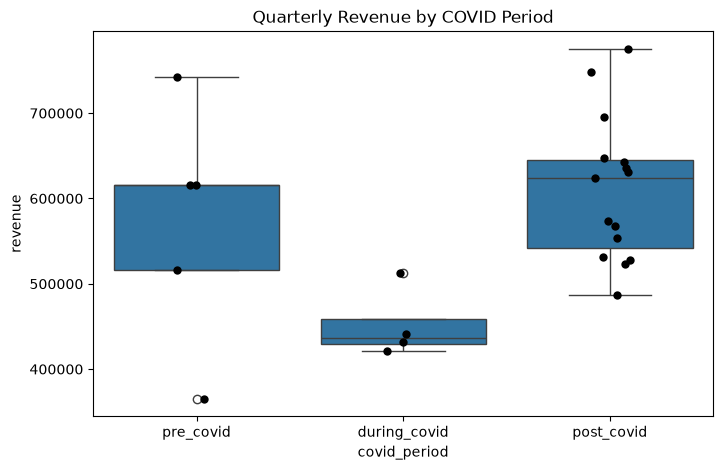

In [8]:
order = ['pre_covid', 'during_covid', 'post_covid']

plt.figure(figsize=(8, 5))
sns.boxplot(data=combined_ledger, x='covid_period', y='revenue', order=order)
sns.stripplot(data=combined_ledger, x='covid_period', y='revenue', order=order, color='black', size=6, jitter=True)
plt.title('Quarterly Revenue by COVID Period')
plt.show()

In [10]:
from scipy.stats import kruskal

pre = combined_ledger[combined_ledger['covid_period'] == 'pre_covid']['revenue']
during = combined_ledger[combined_ledger['covid_period'] == 'during_covid']['revenue']
post = combined_ledger[combined_ledger['covid_period'] == 'post_covid']['revenue']

results = kruskal(pre, during, post)
print("Kruskal-Wallis test results:", results)

Kruskal-Wallis test results: KruskalResult(statistic=np.float64(8.150333333333336), pvalue=np.float64(0.016989382877179417))


In [11]:
import scikit_posthocs as sp

dunn_result = sp.posthoc_dunn(
    combined_ledger, 
    val_col='revenue', 
    group_col='covid_period', 
    p_adjust='bonferroni'
)
print(dunn_result)

              during_covid  post_covid  pre_covid
during_covid      1.000000    0.013365    0.26904
post_covid        0.013365    1.000000    1.00000
pre_covid         0.269040    1.000000    1.00000


## Findings: Did Revenue Recover After COVID?

Revenue took a real hit during COVID, dropping from an average of ~$571K/quarter 
pre-pandemic to ~$450K/quarter during the worst of it. A Kruskal-Wallis test 
confirms this wasn't just normal quarter-to-quarter noise (p = 0.017).

Post-COVID, revenue climbed back up to ~$614K/quarter on average. The jump from 
during-COVID to post-COVID is statistically significant (p = 0.013), so the 
recovery itself is real.

However, post-COVID revenue is **not statistically different from pre-COVID** 
levels (p = 1.00). In plain terms: the business recovered to where it was before, 
but there's no evidence it grew beyond that. 

**Bottom line**: the recovery is real, but it's a return to baseline, not growth 
past it. Worth keeping in mind before assuming the business is in a stronger 
position now than in 2019.

**Note on inflation**: all figures are in nominal dollars. The dataset applies
an inflation factor rising from 1.00 in 2019 to 1.18 in 2024. 2024 revenue is
about 5% above 2019 nominally, which is roughly 11% below once inflation is
accounted for. So "recovered to baseline" is likely too generous in real terms.